In [7]:
from datasets import load_dataset

# Directly loads the 27,558 image dataset
dataset1 = load_dataset("dpdl-benchmark/malaria")


README.md:   0%|          | 0.00/320 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  332MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/27558 [00:00<?, ? examples/s]

In [8]:
from datasets import load_dataset
# Directly loads the ~327,680 histopathology patches
dataset2 = load_dataset("1aurent/PatchCamelyon")


### Dataset Inspection and Exploration

In this section, we will:
1. Print the structure and basic info of both loaded datasets.
2. Visualize sample images with their labels and dimensions.
3. Analyze the height and width distributions of the Malaria dataset.
4. Resize Malaria images to 96×96 (matching PatchCamelyon resolution) and perform a visual side-by-side comparison to assess quality loss.

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd

# 1. Print Dataset Structures
print("--- Dataset 1: Malaria ---")
print(dataset1)
print("\n--- Dataset 2: PatchCamelyon ---")
print(dataset2)

--- Dataset 1: Malaria ---
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 27558
    })
})

--- Dataset 2: PatchCamelyon ---
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 262144
    })
    valid: Dataset({
        features: ['image', 'label'],
        num_rows: 32768
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 32768
    })
})


Malaria Image Size Statistics:


,Width,Height
count,1000.000000,1000.000000
mean,132.778000,133.381000
std,20.494456,20.254878
min,61.000000,79.000000
25%,121.000000,121.000000
50%,130.000000,133.000000
75%,142.000000,145.000000
max,250.000000,232.000000


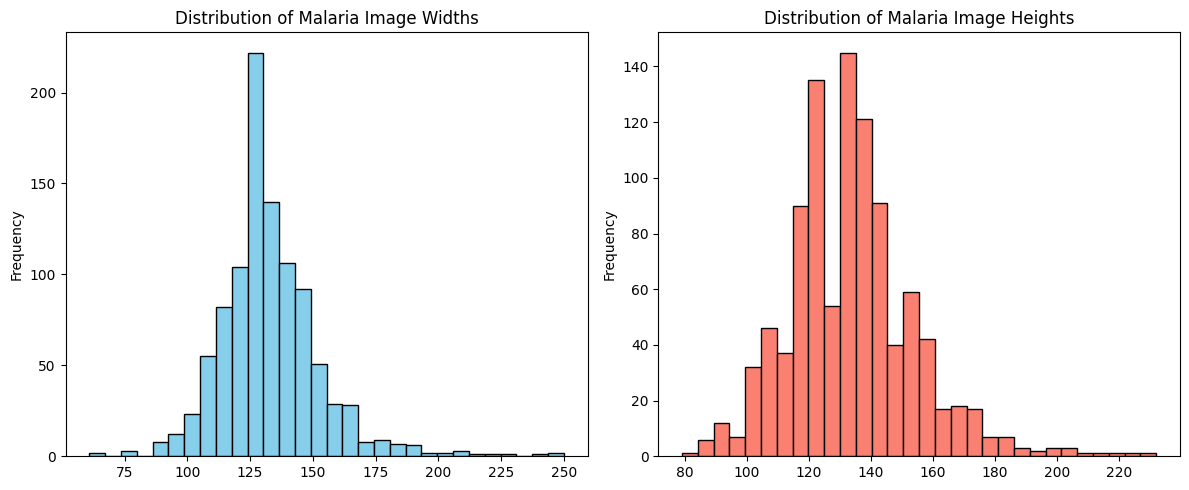

In [10]:
# 2. Analyze Malaria Image Size Distributions
widths = []
heights = []

# Sample a subset of Malaria dataset (e.g., first 1000 images) to compute size statistics quickly
sample_size = min(1000, len(dataset1['train']))
for i in range(sample_size):
    img = dataset1['train'][i]['image']
    widths.append(img.width)
    heights.append(img.height)

sizes_df = pd.DataFrame({'Width': widths, 'Height': heights})
print("Malaria Image Size Statistics:")
display(sizes_df.describe())

# Plot distribution of Width and Height
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sizes_df['Width'].plot(kind='hist', bins=30, ax=axes[0], title='Distribution of Malaria Image Widths', color='skyblue', edgecolor='black')
sizes_df['Height'].plot(kind='hist', bins=30, ax=axes[1], title='Distribution of Malaria Image Heights', color='salmon', edgecolor='black')
plt.tight_layout()
plt.show()

Displaying samples from PatchCamelyon (split: train)


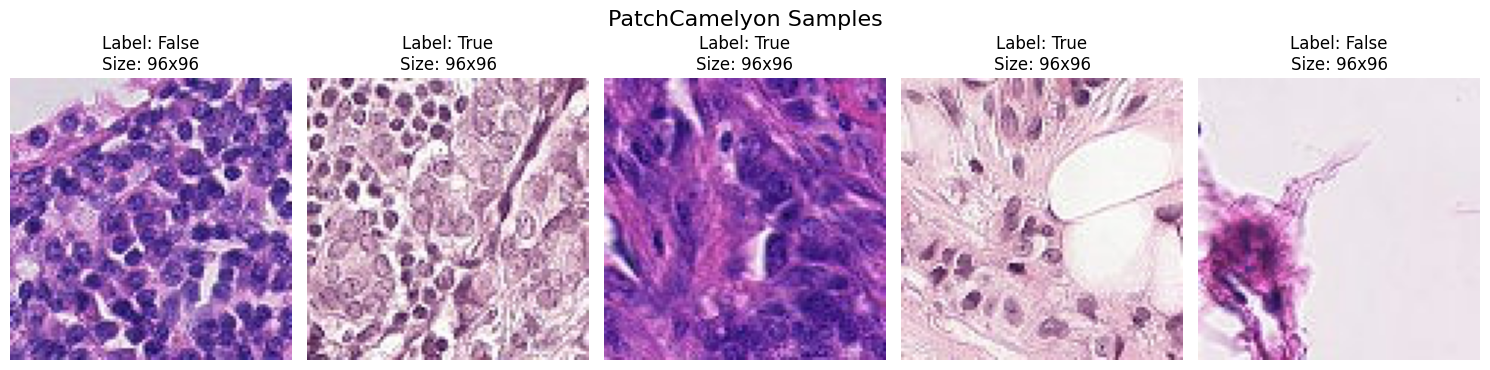

In [11]:
# 3. Visualizing PatchCamelyon (dataset2) sample images
# Typically PatchCamelyon datasets have 'train', 'test', or 'validation' splits.
split_name = list(dataset2.keys())[0]
print(f"Displaying samples from PatchCamelyon (split: {split_name})")

fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for i in range(5):
    sample = dataset2[split_name][i]
    img = sample['image'] if 'image' in sample else sample['img']
    label = sample['label'] if 'label' in sample else 'N/A'

    axes[i].imshow(img)
    axes[i].set_title(f"Label: {label}\nSize: {img.width}x{img.height}")
    axes[i].axis('off')
plt.suptitle("PatchCamelyon Samples", fontsize=16)
plt.tight_layout()
plt.show()

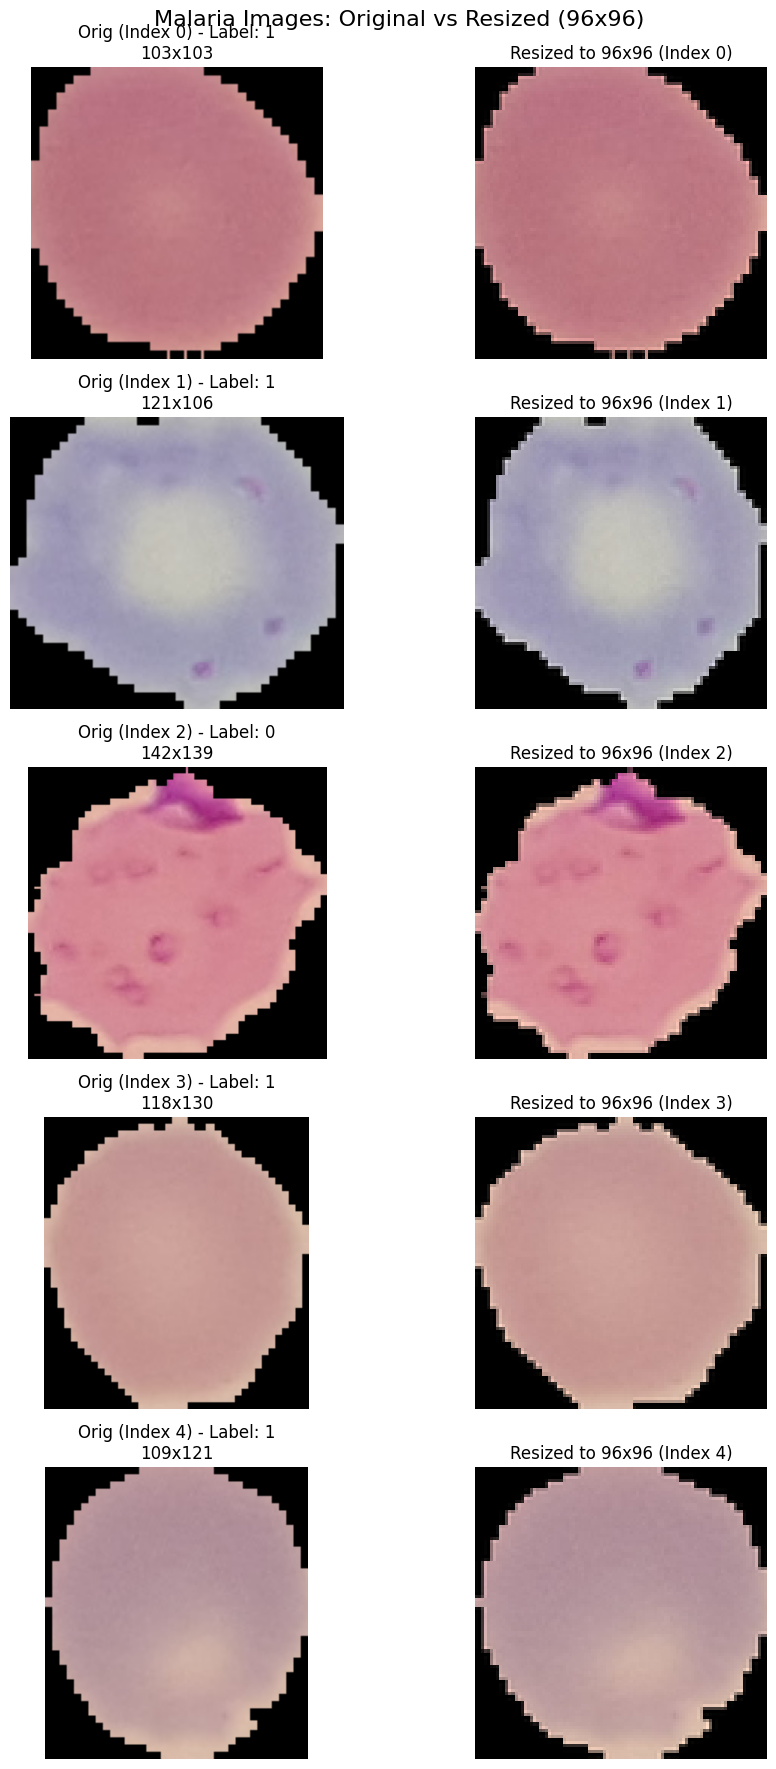

In [12]:
# 4. Visual Comparison: Original vs Resized (96x96) Malaria Images
# We will resize using the Lanczos filter (good for downsampling) to retain maximum quality.

fig, axes = plt.subplots(5, 2, figsize=(10, 18))
for i in range(5):
    sample = dataset1['train'][i]
    orig_img = sample['image']
    label = sample['label'] if 'label' in sample else 'N/A'

    # Resize to 96x96
    resized_img = orig_img.resize((96, 96), Image.Resampling.LANCZOS)

    # Plot original
    axes[i, 0].imshow(orig_img)
    axes[i, 0].set_title(f"Orig (Index {i}) - Label: {label}\n{orig_img.width}x{orig_img.height}")
    axes[i, 0].axis('off')

    # Plot resized
    axes[i, 1].imshow(resized_img)
    axes[i, 1].set_title(f"Resized to 96x96 (Index {i})")
    axes[i, 1].axis('off')

plt.suptitle("Malaria Images: Original vs Resized (96x96)", fontsize=16)
plt.tight_layout()
plt.show()

In [13]:
!pip install -q kaggle

In [14]:
from google.colab import userdata
import os

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

print("Kaggle authentication configured!")

Kaggle authentication configured!


In [15]:
!kaggle datasets list -s malaria

ref                                                 title                                                     size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------  --------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
imdevskp/malaria-dataset                            Malaria Dataset                                          53674  2020-07-01 17:28:22.467000          12788        161                1  
iarunava/cell-images-for-detecting-malaria          Malaria Cell Images Dataset                          708172590  2018-12-05 05:40:21.920000          84897       1354            0.625  
lydia70/malaria-in-africa                           Malaria in Africa                                        27285  2020-12-30 13:40:12.337000           5754         70                1  
kmader/malaria-bounding-boxes                       Malaria 

In [16]:
import os
import zipfile

dataset_name = 'iarunava/cell-images-for-detecting-malaria'
extract_dir = './malaria_kaggle'

# We check if the main directory structure already exists
expected_parasitized = os.path.join(extract_dir, 'cell_images', 'Parasitized')
expected_uninfected = os.path.join(extract_dir, 'cell_images', 'Uninfected')

if os.path.exists(expected_parasitized) and os.path.exists(expected_uninfected):
    print("Dataset already downloaded and extracted!")
    print(f"Parasitized folder: {expected_parasitized}")
    print(f"Uninfected folder: {expected_uninfected}")
else:
    print("Downloading dataset from Kaggle...")
    # Download the dataset
    !kaggle datasets download -d {dataset_name} -p {extract_dir}

    # Find the downloaded zip file
    zip_path = os.path.join(extract_dir, 'cell-images-for-detecting-malaria.zip')
    if os.path.exists(zip_path):
        print("Extracting dataset...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_dir)
        print("Extraction complete!")
        # Clean up the zip file to save space
        os.remove(zip_path)
    else:
        print("Error: Download zip file not found!")

# Verify folders after download/extraction
if os.path.exists(expected_parasitized) and os.path.exists(expected_uninfected):
    print("\nVerification successful!")
    print(f"Parasitized images found: {len(os.listdir(expected_parasitized))}")
    print(f"Uninfected images found: {len(os.listdir(expected_uninfected))}")
else:
    print("\nVerification failed. Please check the directory structure.")

Dataset URL: https://www.kaggle.com/datasets/iarunava/cell-images-for-detecting-malaria
License(s): unknown
100% 675M/675M [00:05<00:00, 136MB/s]

Extracting dataset...
Extraction complete!

Verification successful!
Parasitized images found: 13780
Uninfected images found: 13780


In [17]:
from datasets import load_dataset
import os

# Adjust data directory to the actual folder containing Parasitized and Uninfected subfolders
actual_data_dir = "./malaria_kaggle/cell_images/cell_images"
if not os.path.exists(os.path.join(actual_data_dir, "Parasitized")):
    actual_data_dir = "./malaria_kaggle/cell_images"

dataset1 = load_dataset("imagefolder", data_dir=actual_data_dir)

print("\n--- Loaded dataset1 structure ---")
print(dataset1)

Resolving data files:   0%|          | 0/27560 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]


--- Loaded dataset1 structure ---
DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 27558
    })
})


In [18]:
# Inspect the dataset characteristics
train_set = dataset1["train"]

# Class mapping information
features = train_set.features
print("Features structure:", features)

if "label" in features:
    label_feature = features["label"]
    print("Class Labels:", label_feature.names)

    # Count images in each class
    labels_list = train_set["label"]
    parasitized_count = labels_list.count(label_feature.str2int("Parasitized"))
    uninfected_count = labels_list.count(label_feature.str2int("Uninfected"))

    print(f"\nTotal Images: {len(train_set)}")
    print(f" - Parasitized: {parasitized_count}")
    print(f" - Uninfected: {uninfected_count}")

    # Inspect details of a few sample images (without modifying them)
    print("\nSample image details (first 3 examples):")
    for i in range(3):
        sample = train_set[i]
        img = sample["image"]
        print(f"Sample {i}: Format={img.format}, Mode={img.mode}, Size={img.size}, Class={label_feature.int2str(sample['label'])}")
else:
    print("Error: 'label' feature still missing from dataset features. Check local folders.")

Features structure: {'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['Parasitized', 'Uninfected'])}
Class Labels: ['Parasitized', 'Uninfected']

Total Images: 27558
 - Parasitized: 13779
 - Uninfected: 13779

Sample image details (first 3 examples):
Sample 0: Format=PNG, Mode=RGB, Size=(142, 148), Class=Parasitized
Sample 1: Format=PNG, Mode=RGB, Size=(148, 208), Class=Parasitized
Sample 2: Format=PNG, Mode=RGB, Size=(139, 151), Class=Parasitized


In [19]:
import os
import pandas as pd

# Define paths to image directories
parasitized_dir = "./malaria_kaggle/cell_images/cell_images/Parasitized"
uninfected_dir = "./malaria_kaggle/cell_images/cell_images/Uninfected"

# Retrieve file names
parasitized_files = sorted([f for f in os.listdir(parasitized_dir) if f.endswith('.png')])
uninfected_files = sorted([f for f in os.listdir(uninfected_dir) if f.endswith('.png')])

print("Sample filenames from 'Parasitized':")
for f in parasitized_files[:10]:
    print(f" - {f}")

print("\nSample filenames from 'Uninfected':")
for f in uninfected_files[:10]:
    print(f" - {f}")

Sample filenames from 'Parasitized':
 - C100P61ThinF_IMG_20150918_144104_cell_162.png
 - C100P61ThinF_IMG_20150918_144104_cell_163.png
 - C100P61ThinF_IMG_20150918_144104_cell_164.png
 - C100P61ThinF_IMG_20150918_144104_cell_165.png
 - C100P61ThinF_IMG_20150918_144104_cell_166.png
 - C100P61ThinF_IMG_20150918_144104_cell_167.png
 - C100P61ThinF_IMG_20150918_144104_cell_168.png
 - C100P61ThinF_IMG_20150918_144104_cell_169.png
 - C100P61ThinF_IMG_20150918_144104_cell_170.png
 - C100P61ThinF_IMG_20150918_144104_cell_171.png

Sample filenames from 'Uninfected':
 - C100P61ThinF_IMG_20150918_144104_cell_128.png
 - C100P61ThinF_IMG_20150918_144104_cell_131.png
 - C100P61ThinF_IMG_20150918_144104_cell_144.png
 - C100P61ThinF_IMG_20150918_144104_cell_21.png
 - C100P61ThinF_IMG_20150918_144104_cell_25.png
 - C100P61ThinF_IMG_20150918_144104_cell_34.png
 - C100P61ThinF_IMG_20150918_144104_cell_48.png
 - C100P61ThinF_IMG_20150918_144104_cell_65.png
 - C100P61ThinF_IMG_20150918_144348_cell_108.png


In [20]:
import re
import pandas as pd
import os

def parse_filename_robust(filename, label):
    # Ultimate flexible regex capturing Case/Patient ID (Group 1) and an optional Slide ID (Group 2),
    # allowing for files that omit the 'P' slide designation entirely (e.g., C233ThinF).
    pattern = re.compile(
        r'^(C\d+[A-Za-z]*)'           # 1. Patient/Case ID (e.g., C100, C233, C51A)
        r'(P\d+)?'                    # 2. Optional Slide ID (e.g., P61, P8, or None)
        r'.*?'                        # 3. Match any optional intermediary slide type/equipment descriptions
        r'_(IMG_\d+_[a-zA-Z0-9]+)'    # 4. Base Image ID (e.g., IMG_20150714_094054)
        r'_cell_\d+\.png$'
    )

    match = pattern.match(filename)
    if match:
        patient_id = match.group(1)
        slide_num = match.group(2) if match.group(2) else "P1"
        image_id = match.group(3)
        slide_case_id = f"{patient_id}_{slide_num}"
        return {
            "filename": filename,
            "label": label,
            "patient_id": patient_id,
            "slide_id": slide_num,
            "slide_case_id": slide_case_id,
            "image_id": image_id,
            "status": "parsed"
        }
    else:
        return {
            "filename": filename,
            "label": label,
            "patient_id": None,
            "slide_id": None,
            "slide_case_id": None,
            "image_id": None,
            "status": "unparsed"
        }

# Re-gather and parse files from both classes
records = []
for f in os.listdir("./malaria_kaggle/cell_images/cell_images/Parasitized"):
    if f.endswith('.png'):
        records.append(parse_filename_robust(f, "Parasitized"))

for f in os.listdir("./malaria_kaggle/cell_images/cell_images/Uninfected"):
    if f.endswith('.png'):
        records.append(parse_filename_robust(f, "Uninfected"))

df_meta = pd.DataFrame(records)

print("Robust Parsing Summary:")
print(df_meta["status"].value_counts())

# Filter parsed files
df_parsed = df_meta[df_meta["status"] == "parsed"]

print(f"\nUnique Patient/Case IDs: {df_parsed['patient_id'].nunique()}")
print(f"Unique Slide IDs: {df_parsed['slide_id'].nunique()}")
print(f"Unique Slide-Case Combinations: {df_parsed['slide_case_id'].nunique()}")
print(f"Unique Base Slide Images: {df_parsed['image_id'].nunique()}")

# Check if any remain unparsed
unparsed_df = df_meta[df_meta["status"] == "unparsed"]
if len(unparsed_df) > 0:
    print(f"\nWarning: {len(unparsed_df)} files still unparsed. Examples:")
    print(unparsed_df["filename"].head(10).tolist())
else:
    print("\nSuccess: 100% of filenames parsed successfully!")

Robust Parsing Summary:
status
parsed    27558
Name: count, dtype: int64

Unique Patient/Case IDs: 200
Unique Slide IDs: 1
Unique Slide-Case Combinations: 200
Unique Base Slide Images: 1408

Success: 100% of filenames parsed successfully!


In [21]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

# Ensure reproducibility
np.random.seed(42)

# Create a mapping of patient_id to class counts
patient_stats = df_parsed.groupby('patient_id')['label'].value_counts().unstack(fill_value=0)
patient_stats['total'] = patient_stats['Parasitized'] + patient_stats['Uninfected']

# Group patients into Train, Val, and Test splits using patient_id directly
unique_patients = df_parsed['patient_id'].unique()
train_patients, temp_patients = train_test_split(unique_patients, test_size=0.4, random_state=42)
val_patients, test_patients = train_test_split(temp_patients, test_size=0.5, random_state=42)

# Assign splits in the main dataframe
df_parsed = df_parsed.copy()
df_parsed.loc[df_parsed['patient_id'].isin(train_patients), 'split'] = 'train'
df_parsed.loc[df_parsed['patient_id'].isin(val_patients), 'split'] = 'val'
df_parsed.loc[df_parsed['patient_id'].isin(test_patients), 'split'] = 'test'

# Define targeting strategy: 3000 Parasitized / 3000 Uninfected overall
# Distributed as: Train (2000 P, 2000 U), Val (500 P, 500 U), Test (500 P, 500 U)
split_targets = {
    'train': {'Parasitized': 2000, 'Uninfected': 2000},
    'val': {'Parasitized': 500, 'Uninfected': 500},
    'test': {'Parasitized': 500, 'Uninfected': 500}
}

selected_records = []
for split, targets in split_targets.items():
    for label, count in targets.items():
        sub_df = df_parsed[(df_parsed['split'] == split) & (df_parsed['label'] == label)]
        # Sample the exact required count
        sampled_sub_df = sub_df.sample(n=count, random_state=42)
        selected_records.append(sampled_sub_df)

# Combine sampled splits
df_final_splits = pd.concat(selected_records).reset_index(drop=True)

# Generate relative filepath references
def build_path(row):
    return f"cell_images/{row['label']}/{row['filename']}"

df_final_splits['filepath'] = df_final_splits.apply(build_path, axis=1)

# Create CSV manifests
train_manifest = df_final_splits[df_final_splits['split'] == 'train'][['filepath', 'label', 'patient_id']]
val_manifest = df_final_splits[df_final_splits['split'] == 'val'][['filepath', 'label', 'patient_id']]
test_manifest = df_final_splits[df_final_splits['split'] == 'test'][['filepath', 'label', 'patient_id']]

train_manifest.to_csv('malaria_train.csv', index=False)
val_manifest.to_csv('malaria_val.csv', index=False)
test_manifest.to_csv('malaria_test.csv', index=False)

# Verification Tests
print("=== Manifest Verification Summary ===")
print(f"Train size (Target 4000): {len(train_manifest)} | Parasitized: {len(train_manifest[train_manifest['label']=='Parasitized'])} | Uninfected: {len(train_manifest[train_manifest['label']=='Uninfected'])}")
print(f"Val size   (Target 1000): {len(val_manifest)} | Parasitized: {len(val_manifest[val_manifest['label']=='Parasitized'])} | Uninfected: {len(val_manifest[val_manifest['label']=='Uninfected'])}")
print(f"Test size  (Target 1000): {len(test_manifest)} | Parasitized: {len(test_manifest[test_manifest['label']=='Parasitized'])} | Uninfected: {len(test_manifest[test_manifest['label']=='Uninfected'])}")

# Intersect check for Data Leakage
train_pats = set(train_manifest['patient_id'])
val_pats = set(val_manifest['patient_id'])
test_pats = set(test_manifest['patient_id'])

overlap_train_val = train_pats.intersection(val_pats)
overlap_train_test = train_pats.intersection(test_pats)
overlap_val_test = val_pats.intersection(test_pats)

print("\n=== Data Leakage Intersection Check ===")
print(f"Overlap Train-Val (Should be 0): {len(overlap_train_val)}")
print(f"Overlap Train-Test (Should be 0): {len(overlap_train_test)}")
print(f"Overlap Val-Test (Should be 0): {len(overlap_val_test)}")

if len(overlap_train_val) == 0 and len(overlap_train_test) == 0 and len(overlap_val_test) == 0:
    print("\nLeakage Test Passed: Zero patient-level contamination across splits!")
else:
    print("\nLeakage Test Failed: Patient identifiers overlap across splits!")

=== Manifest Verification Summary ===
Train size (Target 4000): 4000 | Parasitized: 2000 | Uninfected: 2000
Val size   (Target 1000): 1000 | Parasitized: 500 | Uninfected: 500
Test size  (Target 1000): 1000 | Parasitized: 500 | Uninfected: 500

=== Data Leakage Intersection Check ===
Overlap Train-Val (Should be 0): 0
Overlap Train-Test (Should be 0): 0
Overlap Val-Test (Should be 0): 0

Leakage Test Passed: Zero patient-level contamination across splits!


In [22]:
# Inspect some unparsed filenames to adjust our regex pattern
unparsed_samples = df_meta[df_meta["status"] == "unparsed"]["filename"].head(20)
print("Sample Unparsed Filenames:")
for f in unparsed_samples:
    print(f" - {f}")

Sample Unparsed Filenames:


In [23]:

import pandas as pd

base_url = "https://data.lhncbc.nlm.nih.gov/public/Malaria/"

parasitized_url = base_url + "patientid_cellmapping_parasitized.csv"
uninfected_url = base_url + "patientid_cellmapping_uninfected.csv"

parasitized_mapping = pd.read_csv(parasitized_url)
uninfected_mapping = pd.read_csv(uninfected_url)

print("Parasitized mapping:")
display(parasitized_mapping.head())

print("Uninfected mapping:")
display(uninfected_mapping.head())


Parasitized mapping:


,C100P61ThinF,['C100P61ThinF_IMG_20150918_144104_cell_162.png','C100P61ThinF_IMG_20150918_144104_cell_163.png','C100P61ThinF_IMG_20150918_144104_cell_164.png','C100P61ThinF_IMG_20150918_144104_cell_165.png','C100P61ThinF_IMG_20150918_144104_cell_166.png','C100P61ThinF_IMG_20150918_144104_cell_167.png','C100P61ThinF_IMG_20150918_144104_cell_168.png','C100P61ThinF_IMG_20150918_144104_cell_169.png','C100P61ThinF_IMG_20150918_144104_cell_170.png',...,Unnamed: 624,Unnamed: 625,Unnamed: 626,Unnamed: 627,Unnamed: 628,Unnamed: 629,Unnamed: 630,Unnamed: 631,Unnamed: 632,Unnamed: 633
0,C101P62ThinF,['C101P62ThinF_IMG_20150918_151006_cell_61.png','C101P62ThinF_IMG_20150918_151006_cell_62.png','C101P62ThinF_IMG_20150918_151006_cell_63.png','C101P62ThinF_IMG_20150918_151006_cell_64.png','C101P62ThinF_IMG_20150918_151006_cell_65.png','C101P62ThinF_IMG_20150918_151006_cell_66.png','C101P62ThinF_IMG_20150918_151006_cell_67.png','C101P62ThinF_IMG_20150918_151006_cell_68.png','C101P62ThinF_IMG_20150918_151006_cell_69.png',...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,C102P63ThinF,['C102P63ThinF_IMG_20150918_161508_cell_190.png','C102P63ThinF_IMG_20150918_161508_cell_191.png','C102P63ThinF_IMG_20150918_161508_cell_192.png','C102P63ThinF_IMG_20150918_161508_cell_193.png','C102P63ThinF_IMG_20150918_161508_cell_194.png','C102P63ThinF_IMG_20150918_161508_cell_195.png','C102P63ThinF_IMG_20150918_161826_cell_170.png','C102P63ThinF_IMG_20150918_161826_cell_171.png','C102P63ThinF_IMG_20150918_161826_cell_172.png',...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,C103P64ThinF,['C103P64ThinF_IMG_20150918_164250_cell_170.png','C103P64ThinF_IMG_20150918_164250_cell_171.png','C103P64ThinF_IMG_20150918_164250_cell_172.png','C103P64ThinF_IMG_20150918_164250_cell_173.png','C103P64ThinF_IMG_20150918_164250_cell_174.png','C103P64ThinF_IMG_20150918_164250_cell_175.png','C103P64ThinF_IMG_20150918_164331_cell_184.png','C103P64ThinF_IMG_20150918_164331_cell_185.png','C103P64ThinF_IMG_20150918_164331_cell_186.png',...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C104P65ThinF,['C104P65ThinF_IMG_20150918_170850_cell_204.png','C104P65ThinF_IMG_20150918_171154_cell_212.png','C104P65ThinF_IMG_20150918_171154_cell_213.png','C104P65ThinF_IMG_20150918_171751_cell_186.png','C104P65ThinF_IMG_20150918_171751_cell_187.png','C104P65ThinF_IMG_20150918_172053_cell_187.png','C104P65ThinF_IMG_20150918_172537_cell_149.png','C104P65ThinF_IMG_20150918_172639_cell_182.png','C104P65ThinF_IMG_20150918_172639_cell_183.png',...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,C105P66ThinF,['C105P66ThinF_IMG_20150924_094800_cell_136.png','C105P66ThinF_IMG_20150924_094800_cell_137.png','C105P66ThinF_IMG_20150924_095034_cell_148.png','C105P66ThinF_IMG_20150924_095034_cell_149.png','C105P66ThinF_IMG_20150924_095034_cell_150.png','C105P66ThinF_IMG_20150924_095130_cell_155.png','C105P66ThinF_IMG_20150924_095130_cell_156.png','C105P66ThinF_IMG_20150924_095130_cell_157.png','C105P66ThinF_IMG_20150924_095130_cell_158.png',...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Uninfected mapping:


,C100P61ThinF,['C100P61ThinF_IMG_20150918_144104_cell_128.png','C100P61ThinF_IMG_20150918_144104_cell_131.png','C100P61ThinF_IMG_20150918_144104_cell_144.png','C100P61ThinF_IMG_20150918_144104_cell_21.png','C100P61ThinF_IMG_20150918_144104_cell_25.png','C100P61ThinF_IMG_20150918_144104_cell_34.png','C100P61ThinF_IMG_20150918_144104_cell_48.png','C100P61ThinF_IMG_20150918_144104_cell_65.png','C100P61ThinF_IMG_20150918_144348_cell_108.png',...,'C100P61ThinF_IMG_20150918_150041_cell_76.png'],Unnamed: 69,Unnamed: 70,Unnamed: 71,Unnamed: 72,Unnamed: 73,Unnamed: 74,Unnamed: 75,Unnamed: 76,Unnamed: 77
0,C101P62ThinF,['C101P62ThinF_IMG_20150918_151006_cell_17.png','C101P62ThinF_IMG_20150918_151006_cell_29.png','C101P62ThinF_IMG_20150918_151006_cell_32.png','C101P62ThinF_IMG_20150918_151006_cell_53.png','C101P62ThinF_IMG_20150918_151006_cell_56.png','C101P62ThinF_IMG_20150918_151006_cell_59.png','C101P62ThinF_IMG_20150918_151006_cell_8.png','C101P62ThinF_IMG_20150918_151149_cell_23.png','C101P62ThinF_IMG_20150918_151149_cell_28.png',...,'C101P62ThinF_IMG_20150923_170344_cell_61.png','C101P62ThinF_IMG_20150923_170344_cell_66.png','C101P62ThinF_IMG_20150923_170344_cell_69.png','C101P62ThinF_IMG_20150923_170344_cell_70.png'],NaN,NaN,NaN,NaN,NaN,NaN
1,C102P63ThinF,['C102P63ThinF_IMG_20150918_161508_cell_101.png','C102P63ThinF_IMG_20150918_161508_cell_113.png','C102P63ThinF_IMG_20150918_161508_cell_133.png','C102P63ThinF_IMG_20150918_161508_cell_14.png','C102P63ThinF_IMG_20150918_161508_cell_143.png','C102P63ThinF_IMG_20150918_161508_cell_150.png','C102P63ThinF_IMG_20150918_161508_cell_172.png','C102P63ThinF_IMG_20150918_161508_cell_175.png','C102P63ThinF_IMG_20150918_161508_cell_37.png',...,'C102P63ThinF_IMG_20150918_163054_cell_87.png'],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,C103P64ThinF,['C103P64ThinF_IMG_20150918_164250_cell_121.png','C103P64ThinF_IMG_20150918_164250_cell_128.png','C103P64ThinF_IMG_20150918_164250_cell_15.png','C103P64ThinF_IMG_20150918_164250_cell_153.png','C103P64ThinF_IMG_20150918_164250_cell_164.png','C103P64ThinF_IMG_20150918_164250_cell_19.png','C103P64ThinF_IMG_20150918_164250_cell_28.png','C103P64ThinF_IMG_20150918_164250_cell_39.png','C103P64ThinF_IMG_20150918_164250_cell_67.png',...,'C103P64ThinF_IMG_20150918_165510_cell_98.png'],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,C104P65ThinF,['C104P65ThinF_IMG_20150918_170850_cell_140.png','C104P65ThinF_IMG_20150918_170850_cell_167.png','C104P65ThinF_IMG_20150918_170850_cell_174.png','C104P65ThinF_IMG_20150918_170850_cell_189.png','C104P65ThinF_IMG_20150918_170850_cell_29.png','C104P65ThinF_IMG_20150918_170850_cell_32.png','C104P65ThinF_IMG_20150918_170850_cell_66.png','C104P65ThinF_IMG_20150918_170850_cell_68.png','C104P65ThinF_IMG_20150918_170850_cell_83.png',...,'C104P65ThinF_IMG_20150918_172639_cell_34.png','C104P65ThinF_IMG_20150918_172639_cell_44.png','C104P65ThinF_IMG_20150918_172639_cell_5.png','C104P65ThinF_IMG_20150918_172639_cell_93.png','C104P65ThinF_IMG_20150918_172639_cell_95.png'],NaN,NaN,NaN,NaN,NaN
4,C105P66ThinF,['C105P66ThinF_IMG_20150924_094800_cell_11.png','C105P66ThinF_IMG_20150924_094800_cell_132.png','C105P66ThinF_IMG_20150924_094800_cell_30.png','C105P66ThinF_IMG_20150924_094800_cell_39.png','C105P66ThinF_IMG_20150924_094800_cell_62.png','C105P66ThinF_IMG_20150924_094800_cell_63.png','C105P66ThinF_IMG_20150924_094800_cell_70.png','C105P66ThinF_IMG_20150924_094800_cell_74.png','C105P66ThinF_IMG_20150924_094800_cell_90.png',...,'C105P66ThinF_IMG_20150924_100655_cell_96.png'],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [24]:
print("Parasitized mapping:")
print("Columns:", parasitized_mapping.shape[1])
print("First 5 group names:")
print(parasitized_mapping.columns[:5].tolist())

print("\nFirst group — first 5 filenames:")
print(parasitized_mapping.iloc[:5, 0].tolist())

print("\nUninfected mapping:")
print("Columns:", uninfected_mapping.shape[1])
print("First 5 group names:")
print(uninfected_mapping.columns[:5].tolist())

Parasitized mapping:
Columns: 634
First 5 group names:
['C100P61ThinF', "['C100P61ThinF_IMG_20150918_144104_cell_162.png'", " 'C100P61ThinF_IMG_20150918_144104_cell_163.png'", " 'C100P61ThinF_IMG_20150918_144104_cell_164.png'", " 'C100P61ThinF_IMG_20150918_144104_cell_165.png'"]

First group — first 5 filenames:
['C101P62ThinF', 'C102P63ThinF', 'C103P64ThinF', 'C104P65ThinF', 'C105P66ThinF']

Uninfected mapping:
Columns: 78
First 5 group names:
['C100P61ThinF', "['C100P61ThinF_IMG_20150918_144104_cell_128.png'", " 'C100P61ThinF_IMG_20150918_144104_cell_131.png'", " 'C100P61ThinF_IMG_20150918_144104_cell_144.png'", " 'C100P61ThinF_IMG_20150918_144104_cell_21.png'"]


In [27]:

import os
import re
import csv
import io
import urllib.request
import numpy as np
import pandas as pd
from collections import defaultdict

# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

DATA_DIR = "./malaria_kaggle/cell_images/cell_images"

PARASITIZED_DIR = os.path.join(DATA_DIR, "Parasitized")
UNINFECTED_DIR = os.path.join(DATA_DIR, "Uninfected")

BASE_URL = "https://data.lhncbc.nlm.nih.gov/public/Malaria/"

MAPPING_URLS = {
    "Parasitized": BASE_URL + "patientid_cellmapping_parasitized.csv",
    "Uninfected": BASE_URL + "patientid_cellmapping_uninfected.csv"
}

SEED = 42

TARGETS = {
    "train": {"Parasitized": 2000, "Uninfected": 2000},
    "val":   {"Parasitized": 500,  "Uninfected": 500},
    "test":  {"Parasitized": 500,  "Uninfected": 500}
}

# Check dataset folders
assert os.path.isdir(PARASITIZED_DIR), "Parasitized folder not found!"
assert os.path.isdir(UNINFECTED_DIR), "Uninfected folder not found!"

print("Dataset folders verified.")


# ============================================================
# 2. READ OFFICIAL NIH MAPPING FILES
# ============================================================

def read_mapping(url, label):

    response = urllib.request.urlopen(url)
    raw_text = response.read().decode("utf-8-sig")

    reader = csv.reader(io.StringIO(raw_text))

    records = []

    for row_number, row in enumerate(reader, start=1):

        if not row:
            continue

        # First field identifies the official group
        group_id = row[0].strip().strip("[]'\" ")

        # Extract the patient identifier.
        # Do NOT invent a default if it is missing.
        patient_match = re.search(r"P\d+", group_id)

        if not patient_match:
            raise ValueError(
                f"Could not identify patient ID in mapping row "
                f"{row_number}: {group_id}"
            )

        patient_id = patient_match.group(0)

        # Remaining fields contain the filenames
        filenames = []

        for field in row[1:]:
            found = re.findall(
                r"[A-Za-z0-9_]+\.png",
                field,
                flags=re.IGNORECASE
            )
            filenames.extend(found)

        for filename in filenames:
            records.append({
                "filename": filename,
                "label": label,
                "group_id": group_id,
                "patient_id": patient_id
            })

    return pd.DataFrame(records)


parasitized_map = read_mapping(
    MAPPING_URLS["Parasitized"], "Parasitized"
)

uninfected_map = read_mapping(
    MAPPING_URLS["Uninfected"], "Uninfected"
)

mapping_df = pd.concat(
    [parasitized_map, uninfected_map],
    ignore_index=True
)

print("\n=== Official Mapping Summary ===")
print("Parasitized mapping entries:", len(parasitized_map))
print("Uninfected mapping entries:", len(uninfected_map))
print("Total mapping entries:", len(mapping_df))
print("Unique patient IDs:", mapping_df["patient_id"].nunique())
print("Unique group IDs:", mapping_df["group_id"].nunique())


# ============================================================
# 3. CHECK DUPLICATE MAPPING ENTRIES
# ============================================================

duplicate_files = mapping_df[
    mapping_df.duplicated(
        subset=["filename", "label"],
        keep=False
    )
]

if len(duplicate_files) > 0:
    print("\nDuplicate mapping entries found:")
    print(duplicate_files.head(20))
    raise ValueError("Duplicate filenames in official mapping!")

print("No duplicate filename entries found.")


# ============================================================
# 4. MATCH OFFICIAL MAPPING TO DOWNLOADED IMAGES
# ============================================================

dataset_files = []

for label, folder in [
    ("Parasitized", PARASITIZED_DIR),
    ("Uninfected", UNINFECTED_DIR)
]:
    for filename in os.listdir(folder):
        if filename.lower().endswith(".png"):
            dataset_files.append({
                "filename": filename,
                "label": label,
                "filepath": os.path.join(label, filename)
            })

dataset_df = pd.DataFrame(dataset_files)

print("\n=== Downloaded Dataset Summary ===")
print(dataset_df["label"].value_counts())


# Match on both filename and class
matched_df = dataset_df.merge(
    mapping_df,
    on=["filename", "label"],
    how="left",
    validate="one_to_one"
)

# Find images that have no official mapping
unmatched = matched_df[
    matched_df["patient_id"].isna()
]

if len(unmatched) > 0:
    print("\nUnmatched images:", len(unmatched))
    print(unmatched[["filename", "label"]].head(20))
    raise ValueError(
        "Some downloaded images could not be matched to the NIH mapping. "
        "No splits have been created."
    )

# Check mapping entries not present in downloaded dataset
dataset_keys = set(
    zip(dataset_df["filename"], dataset_df["label"])
)

mapping_keys = set(
    zip(mapping_df["filename"], mapping_df["label"])
)

extra_mapping = mapping_keys - dataset_keys

print("\n=== Mapping Match Verification ===")
print("Downloaded images:", len(dataset_df))
print("Successfully matched:", len(matched_df))
print("Mapping entries not in downloaded dataset:", len(extra_mapping))

if len(matched_df) != len(dataset_df):
    raise ValueError("Not all downloaded images were matched!")

print("All downloaded images matched successfully.")


# ============================================================
# 5. BUILD PATIENT-LEVEL GROUP STATISTICS
# ============================================================

patient_stats = (
    matched_df
    .groupby(["patient_id", "label"])
    .size()
    .unstack(fill_value=0)
)

for label in ["Parasitized", "Uninfected"]:
    if label not in patient_stats.columns:
        patient_stats[label] = 0

patient_stats["total"] = (
    patient_stats["Parasitized"]
    + patient_stats["Uninfected"]
)

print("\n=== Patient-Level Statistics ===")
print("Unique patients:", len(patient_stats))
print(patient_stats.head(10))


# ============================================================
# 6. ASSIGN WHOLE PATIENTS TO TRAIN / VAL / TEST
# ============================================================

# Try randomized patient assignments until every split has
# enough images of both classes for the exact target counts.

rng = np.random.default_rng(SEED)

patient_ids = patient_stats.index.to_numpy()

split_assignment = None

MAX_ATTEMPTS = 10000

for attempt in range(MAX_ATTEMPTS):

    shuffled_patients = rng.permutation(patient_ids)

    n = len(shuffled_patients)

    train_end = int(n * 0.60)
    val_end = int(n * 0.80)

    train_patients = shuffled_patients[:train_end]
    val_patients = shuffled_patients[train_end:val_end]
    test_patients = shuffled_patients[val_end:]

    candidate = {
        "train": train_patients,
        "val": val_patients,
        "test": test_patients
    }

    valid = True

    for split, patients in candidate.items():

        available = patient_stats.loc[patients]

        for label, required_count in TARGETS[split].items():

            available_count = int(available[label].sum())

            if available_count < required_count:
                valid = False
                break

        if not valid:
            break

    if valid:
        split_assignment = candidate
        break

if split_assignment is None:
    raise ValueError(
        "Could not find a patient-level assignment satisfying "
        "the required class counts. No manifests have been created."
    )

print("\nValid patient-level assignment found.")
print("Attempts required:", attempt + 1)


# Assign each patient to exactly one split
patient_to_split = {}

for split, patients in split_assignment.items():
    for patient in patients:
        patient_to_split[patient] = split

matched_df["split"] = matched_df["patient_id"].map(
    patient_to_split
)

if matched_df["split"].isna().any():
    raise ValueError("Some patients were not assigned to a split!")


# ============================================================
# 7. SELECT EXACT CLASS-BALANCED IMAGE COUNTS
# ============================================================

selected_parts = []

for split, targets in TARGETS.items():

    for label, required_count in targets.items():

        candidates = matched_df[
            (matched_df["split"] == split)
            & (matched_df["label"] == label)
        ]

        if len(candidates) < required_count:
            raise ValueError(
                f"Insufficient {label} images in {split}."
            )

        selected = candidates.sample(
            n=required_count,
            random_state=SEED
        )

        selected_parts.append(selected)

final_df = pd.concat(
    selected_parts,
    ignore_index=True
)

# Shuffle selected rows for reproducibility
final_df = final_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


# ============================================================
# 8. CREATE CSV MANIFESTS
# ============================================================

manifest_columns = [
    "filepath",
    "filename",
    "label",
    "patient_id",
    "group_id",
    "split"
]

train_manifest = final_df[
    final_df["split"] == "train"
][manifest_columns]

val_manifest = final_df[
    final_df["split"] == "val"
][manifest_columns]

test_manifest = final_df[
    final_df["split"] == "test"
][manifest_columns]

train_manifest.to_csv("malaria_train.csv", index=False)
val_manifest.to_csv("malaria_val.csv", index=False)
test_manifest.to_csv("malaria_test.csv", index=False)

print("\nThree manifests saved successfully.")


# ============================================================
# 9. VERIFY COUNTS AND CLASS BALANCE
# ============================================================

print("\n=== FINAL SPLIT SUMMARY ===")

for split, manifest in [
    ("train", train_manifest),
    ("val", val_manifest),
    ("test", test_manifest)
]:

    print(f"\n{split.upper()}:")
    print("Total:", len(manifest))
    print(manifest["label"].value_counts().to_dict())
    print("Unique patients:", manifest["patient_id"].nunique())
    print("Unique groups:", manifest["group_id"].nunique())


# ============================================================
# 10. VERIFY NO PATIENT LEAKAGE
# ============================================================

train_patients = set(train_manifest["patient_id"])
val_patients = set(val_manifest["patient_id"])
test_patients = set(test_manifest["patient_id"])

overlap_train_val = train_patients & val_patients
overlap_train_test = train_patients & test_patients
overlap_val_test = val_patients & test_patients

print("\n=== PATIENT LEAKAGE CHECK ===")
print("Train-Val overlap:", len(overlap_train_val))
print("Train-Test overlap:", len(overlap_train_test))
print("Val-Test overlap:", len(overlap_val_test))

assert len(overlap_train_val) == 0
assert len(overlap_train_test) == 0
assert len(overlap_val_test) == 0


# ============================================================
# 11. VERIFY EXACT TARGETS AND FILE EXISTENCE
# ============================================================

for split, manifest in [
    ("train", train_manifest),
    ("val", val_manifest),
    ("test", test_manifest)
]:

    assert len(manifest) == sum(TARGETS[split].values())

    for label, expected in TARGETS[split].items():
        actual = (manifest["label"] == label).sum()
        assert actual == expected, (
            f"{split}: expected {expected} {label}, got {actual}"
        )

    for filepath in manifest["filepath"]:
        full_path = os.path.join(DATA_DIR, filepath)
        assert os.path.isfile(full_path), (
            f"Missing image file: {full_path}"
        )

print("\nALL VERIFICATION CHECKS PASSED!")
print("Exact class counts confirmed.")
print("All selected image files exist.")
print("No patient overlap across splits.")


Dataset folders verified.


ValueError: Could not identify patient ID in mapping row 31: C12NThinF

In [28]:

import os
import re
import csv
import io
import urllib.request
import numpy as np
import pandas as pd
from collections import defaultdict

# ============================================================
# 1. PATHS AND SETTINGS
# ============================================================

DATA_DIR = "./malaria_kaggle/cell_images/cell_images"

PARASITIZED_DIR = os.path.join(DATA_DIR, "Parasitized")
UNINFECTED_DIR = os.path.join(DATA_DIR, "Uninfected")

BASE_URL = "https://data.lhncbc.nlm.nih.gov/public/Malaria/"

MAPPING_URLS = {
    "Parasitized": BASE_URL + "patientid_cellmapping_parasitized.csv",
    "Uninfected": BASE_URL + "patientid_cellmapping_uninfected.csv"
}

SEED = 42

TARGETS = {
    "train": {"Parasitized": 2000, "Uninfected": 2000},
    "val":   {"Parasitized": 500,  "Uninfected": 500},
    "test":  {"Parasitized": 500,  "Uninfected": 500}
}

assert os.path.isdir(PARASITIZED_DIR), "Parasitized folder not found!"
assert os.path.isdir(UNINFECTED_DIR), "Uninfected folder not found!"

print("Dataset folders verified.")


# ============================================================
# 2. READ OFFICIAL NIH MAPPING FILES
# ============================================================

def read_mapping(url, label):

    response = urllib.request.urlopen(url)
    raw_text = response.read().decode("utf-8-sig")

    # IMPORTANT:
    # The first CSV row contains data, not column headers.
    # Each row starts with a group ID, followed by filename fields.
    reader = csv.reader(io.StringIO(raw_text))

    records = []

    for row_number, row in enumerate(reader, start=1):

        if not row:
            continue

        group_id = row[0].strip().strip("[]'\" ")

        if not group_id:
            continue

        # Extract patient ID only if one genuinely exists.
        patient_match = re.search(r"P\d+", group_id)
        patient_id = patient_match.group(0) if patient_match else None

        filenames = []

        for field in row[1:]:
            found = re.findall(
                r"[A-Za-z0-9_]+\.png",
                field,
                flags=re.IGNORECASE
            )
            filenames.extend(found)

        if not filenames:
            raise ValueError(
                f"No filenames found in mapping row {row_number}: {group_id}"
            )

        for filename in filenames:
            records.append({
                "filename": filename,
                "label": label,
                "group_id": group_id,
                "patient_id": patient_id
            })

    return pd.DataFrame(records)


parasitized_map = read_mapping(
    MAPPING_URLS["Parasitized"], "Parasitized"
)

uninfected_map = read_mapping(
    MAPPING_URLS["Uninfected"], "Uninfected"
)

mapping_df = pd.concat(
    [parasitized_map, uninfected_map],
    ignore_index=True
)

print("\n=== Official Mapping Summary ===")
print("Parasitized mapping entries:", len(parasitized_map))
print("Uninfected mapping entries:", len(uninfected_map))
print("Total mapping entries:", len(mapping_df))
print("Unique group IDs:", mapping_df["group_id"].nunique())
print("Unique identifiable patient IDs:", mapping_df["patient_id"].nunique())
print(
    "Groups without an identifiable patient ID:",
    mapping_df.loc[
        mapping_df["patient_id"].isna(), "group_id"
    ].nunique()
)


# ============================================================
# 3. CHECK DUPLICATE MAPPING ENTRIES
# ============================================================

duplicate_files = mapping_df[
    mapping_df.duplicated(
        subset=["filename", "label"],
        keep=False
    )
]

if len(duplicate_files) > 0:
    print("\nDuplicate mapping entries:")
    print(duplicate_files.head(20))
    raise ValueError("Duplicate filename entries in official mapping!")

print("No duplicate filename-label entries found.")

# A filename must not be assigned to two different classes.
cross_label_duplicates = mapping_df[
    mapping_df.duplicated(
        subset=["filename"],
        keep=False
    )
]

if len(cross_label_duplicates) > 0:
    print(cross_label_duplicates.head(20))
    raise ValueError("A filename appears under multiple labels!")


# ============================================================
# 4. MATCH OFFICIAL MAPPING TO DOWNLOADED IMAGES
# ============================================================

dataset_files = []

for label, folder in [
    ("Parasitized", PARASITIZED_DIR),
    ("Uninfected", UNINFECTED_DIR)
]:

    for filename in os.listdir(folder):

        if filename.lower().endswith(".png"):

            dataset_files.append({
                "filename": filename,
                "label": label,
                "filepath": os.path.join(label, filename)
            })

dataset_df = pd.DataFrame(dataset_files)

print("\n=== Downloaded Dataset Summary ===")
print(dataset_df["label"].value_counts())

matched_df = dataset_df.merge(
    mapping_df,
    on=["filename", "label"],
    how="left",
    validate="one_to_one"
)

# Check unmatched downloaded images.
unmatched = matched_df[matched_df["group_id"].isna()]

if len(unmatched) > 0:
    print("\nUnmatched images:", len(unmatched))
    print(unmatched[["filename", "label"]].head(20))
    raise ValueError(
        "Some downloaded images could not be matched. "
        "No manifests have been saved."
    )

dataset_keys = set(
    zip(dataset_df["filename"], dataset_df["label"])
)

mapping_keys = set(
    zip(mapping_df["filename"], mapping_df["label"])
)

extra_mapping = mapping_keys - dataset_keys

print("\n=== Mapping Match Verification ===")
print("Downloaded images:", len(dataset_df))
print("Successfully matched:", len(matched_df))
print("Mapping entries not in downloaded dataset:", len(extra_mapping))

if len(matched_df) != len(dataset_df):
    raise ValueError("Not all downloaded images were matched!")

print("All downloaded images matched successfully.")


# ============================================================
# 5. CREATE A SAFE SPLIT GROUP
# ============================================================

# If a patient ID exists, use it to keep all their mapped groups
# together. Otherwise, use the complete official group ID.
#
# This prevents splitting known patients across datasets.
# Missing patient IDs are NOT fabricated.

matched_df["split_group_id"] = matched_df.apply(
    lambda row: (
        "PATIENT_" + row["patient_id"]
        if pd.notna(row["patient_id"])
        else "GROUP_" + row["group_id"]
    ),
    axis=1
)

group_stats = (
    matched_df
    .groupby(["split_group_id", "label"])
    .size()
    .unstack(fill_value=0)
)

for label in ["Parasitized", "Uninfected"]:
    if label not in group_stats.columns:
        group_stats[label] = 0

group_stats["total"] = (
    group_stats["Parasitized"]
    + group_stats["Uninfected"]
)

print("\n=== Split Group Statistics ===")
print("Unique split groups:", len(group_stats))
print("Groups with missing patient IDs:",
      matched_df.loc[
          matched_df["patient_id"].isna(), "group_id"
      ].nunique())


# ============================================================
# 6. ASSIGN WHOLE GROUPS TO TRAIN / VAL / TEST
# ============================================================

rng = np.random.default_rng(SEED)

group_ids = group_stats.index.to_numpy()

split_assignment = None
MAX_ATTEMPTS = 10000

for attempt in range(MAX_ATTEMPTS):

    shuffled_groups = rng.permutation(group_ids)

    n = len(shuffled_groups)

    train_end = int(n * 0.60)
    val_end = int(n * 0.80)

    candidate = {
        "train": shuffled_groups[:train_end],
        "val": shuffled_groups[train_end:val_end],
        "test": shuffled_groups[val_end:]
    }

    valid = True

    for split, groups in candidate.items():

        available = group_stats.loc[groups]

        for label, required_count in TARGETS[split].items():

            available_count = int(available[label].sum())

            if available_count < required_count:
                valid = False
                break

        if not valid:
            break

    if valid:
        split_assignment = candidate
        break

if split_assignment is None:
    raise ValueError(
        "Could not find a group-level assignment satisfying the "
        "required class counts. No manifests have been saved."
    )

print("\nValid group-level assignment found.")
print("Attempts required:", attempt + 1)

group_to_split = {}

for split, groups in split_assignment.items():
    for group in groups:
        group_to_split[group] = split

matched_df["split"] = matched_df["split_group_id"].map(
    group_to_split
)

if matched_df["split"].isna().any():
    raise ValueError("Some groups were not assigned to a split!")


# ============================================================
# 7. SELECT EXACT CLASS-BALANCED IMAGE COUNTS
# ============================================================

selected_parts = []

for split, targets in TARGETS.items():

    for label, required_count in targets.items():

        candidates = matched_df[
            (matched_df["split"] == split)
            & (matched_df["label"] == label)
        ]

        if len(candidates) < required_count:
            raise ValueError(
                f"Insufficient {label} images in {split}."
            )

        selected = candidates.sample(
            n=required_count,
            random_state=SEED
        )

        selected_parts.append(selected)

final_df = pd.concat(
    selected_parts,
    ignore_index=True
)

final_df = final_df.sample(
    frac=1,
    random_state=SEED
).reset_index(drop=True)


# ============================================================
# 8. VERIFY SPLIT GROUP AND PATIENT SEPARATION
# ============================================================

split_groups = {
    split: set(
        final_df.loc[
            final_df["split"] == split, "split_group_id"
        ]
    )
    for split in TARGETS
}

assert split_groups["train"].isdisjoint(split_groups["val"])
assert split_groups["train"].isdisjoint(split_groups["test"])
assert split_groups["val"].isdisjoint(split_groups["test"])

# Verify identifiable patient IDs separately.
patient_sets = {
    split: set(
        final_df.loc[
            (final_df["split"] == split)
            & final_df["patient_id"].notna(),
            "patient_id"
        ]
    )
    for split in TARGETS
}

assert patient_sets["train"].isdisjoint(patient_sets["val"])
assert patient_sets["train"].isdisjoint(patient_sets["test"])
assert patient_sets["val"].isdisjoint(patient_sets["test"])

print("\nGroup separation verified.")
print("Identifiable patient IDs do not overlap across splits.")


# ============================================================
# 9. CREATE CSV MANIFESTS
# ============================================================

manifest_columns = [
    "filepath",
    "filename",
    "label",
    "patient_id",
    "group_id",
    "split_group_id",
    "split"
]

train_manifest = final_df[
    final_df["split"] == "train"
][manifest_columns].copy()

val_manifest = final_df[
    final_df["split"] == "val"
][manifest_columns].copy()

test_manifest = final_df[
    final_df["split"] == "test"
][manifest_columns].copy()


# ============================================================
# 10. FINAL VERIFICATION BEFORE SAVING
# ============================================================

print("\n=== FINAL SPLIT SUMMARY ===")

manifests = {
    "train": train_manifest,
    "val": val_manifest,
    "test": test_manifest
}

for split, manifest in manifests.items():

    print(f"\n{split.upper()}:")
    print("Total:", len(manifest))
    print(manifest["label"].value_counts().to_dict())
    print("Unique split groups:", manifest["split_group_id"].nunique())
    print("Identifiable patients:", manifest["patient_id"].nunique())

    assert len(manifest) == sum(TARGETS[split].values())

    for label, expected in TARGETS[split].items():
        actual = int((manifest["label"] == label).sum())

        assert actual == expected, (
            f"{split}: expected {expected} {label}, got {actual}"
        )

    for filepath in manifest["filepath"]:
        full_path = os.path.join(DATA_DIR, filepath)

        assert os.path.isfile(full_path), (
            f"Missing image file: {full_path}"
        )

# Verify exact selected image counts and no repeated filenames.
assert final_df["filename"].is_unique

print("\nAll count, file-existence and separation checks passed.")


# ============================================================
# 11. SAVE MANIFESTS ONLY AFTER ALL CHECKS PASS
# ============================================================

train_manifest.to_csv("malaria_train.csv", index=False)
val_manifest.to_csv("malaria_val.csv", index=False)
test_manifest.to_csv("malaria_test.csv", index=False)

print("\nThree manifests saved successfully!")
print("malaria_train.csv")
print("malaria_val.csv")
print("malaria_test.csv")


Dataset folders verified.

=== Official Mapping Summary ===
Parasitized mapping entries: 13779
Uninfected mapping entries: 13779
Total mapping entries: 27558
Unique group IDs: 201
Unique identifiable patient IDs: 150
Groups without an identifiable patient ID: 50
No duplicate filename-label entries found.

=== Downloaded Dataset Summary ===
label
Parasitized    13779
Uninfected     13779
Name: count, dtype: int64

=== Mapping Match Verification ===
Downloaded images: 27558
Successfully matched: 27558
Mapping entries not in downloaded dataset: 0
All downloaded images matched successfully.

=== Split Group Statistics ===
Unique split groups: 200
Groups with missing patient IDs: 50

Valid group-level assignment found.
Attempts required: 1

Group separation verified.
Identifiable patient IDs do not overlap across splits.

=== FINAL SPLIT SUMMARY ===

TRAIN:
Total: 4000
{'Parasitized': 2000, 'Uninfected': 2000}
Unique split groups: 120
Identifiable patients: 93

VAL:
Total: 1000
{'Parasitize

In [29]:
import os
import pandas as pd

for filename in [
    "malaria_train.csv",
    "malaria_val.csv",
    "malaria_test.csv"
]:
    print(f"\n{filename}")
    print("Exists:", os.path.exists(filename))

    if os.path.exists(filename):
        df = pd.read_csv(filename)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df["label"].value_counts().to_dict())


malaria_train.csv
Exists: True
Rows: 4000
Columns: ['filepath', 'filename', 'label', 'patient_id', 'group_id', 'split_group_id', 'split']
{'Parasitized': 2000, 'Uninfected': 2000}

malaria_val.csv
Exists: True
Rows: 1000
Columns: ['filepath', 'filename', 'label', 'patient_id', 'group_id', 'split_group_id', 'split']
{'Parasitized': 500, 'Uninfected': 500}

malaria_test.csv
Exists: True
Rows: 1000
Columns: ['filepath', 'filename', 'label', 'patient_id', 'group_id', 'split_group_id', 'split']
{'Parasitized': 500, 'Uninfected': 500}


In [30]:
import pandas as pd
import re

files = {
    "train": "malaria_train.csv",
    "val": "malaria_val.csv",
    "test": "malaria_test.csv"
}

splits = {}

for split, path in files.items():
    df = pd.read_csv(path)

    # Extract the leading C-number from each filename
    df["case_id"] = df["filename"].str.extract(r"^(C\d+)")

    if df["case_id"].isna().any():
        raise ValueError(f"Could not extract C-number in {split}")

    splits[split] = df

# Check whether any C-number occurs in multiple splits
case_sets = {
    split: set(df["case_id"])
    for split, df in splits.items()
}

print("Unique C-numbers:")
for split, cases in case_sets.items():
    print(split, len(cases))

print("\nC-number overlap:")
print("Train-Val:", len(case_sets["train"] & case_sets["val"]))
print("Train-Test:", len(case_sets["train"] & case_sets["test"]))
print("Val-Test:", len(case_sets["val"] & case_sets["test"]))

print("\nTotal unique C-numbers:",
      len(set.union(*case_sets.values())))

Unique C-numbers:
train 120
val 40
test 40

C-number overlap:
Train-Val: 0
Train-Test: 0
Val-Test: 0

Total unique C-numbers: 200


In [31]:
import os
from pathlib import Path

print("Current working directory:", os.getcwd())

print("\n/content contents:")
for item in sorted(Path("/content").iterdir()):
    print(item.name)

print("\nGoogle Drive mounted:", Path("/content/drive/MyDrive").exists())

Current working directory: /content

/content contents:
.config
malaria_kaggle
malaria_test.csv
malaria_train.csv
malaria_val.csv
sample_data

Google Drive mounted: False


In [32]:
from pathlib import Path

p = Path("/content/dataset2")

print("PCam exists:", p.exists())

if p.exists():
    for item in sorted(p.iterdir()):
        print(("DIR  " if item.is_dir() else "FILE ") + item.name)

PCam exists: False


In [33]:
from pathlib import Path

print("Checking PCam...")

for p in Path("/content").rglob("*"):
    if "pcam" in p.name.lower() or "patchcamelyon" in p.name.lower():
        print(p)

Checking PCam...


In [34]:
print(dataset2)

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 262144
    })
    valid: Dataset({
        features: ['image', 'label'],
        num_rows: 32768
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 32768
    })
})


In [35]:

from collections import Counter

splits = ["train", "valid", "test"]

print("=" * 65)
print("PCAM DATASET INSPECTION")
print("=" * 65)

# Check class names, if available
print("\nLabel feature:")
print(dataset2["train"].features["label"])

for split in splits:
    data = dataset2[split]
    counts = Counter(data["label"])

    print(f"\n{split.upper()} PARTITION")
    print("-" * 40)
    print("Total images:", len(data))
    print("Class distribution:")

    for label, count in sorted(counts.items()):
        print(f"  Label {label}: {count}")

# Inspect one image
sample = dataset2["train"][0]["image"]

print("\nIMAGE PROPERTIES")
print("-" * 40)
print("Image type:", type(sample))
print("Image dimensions:", sample.size)
print("Image mode:", sample.mode)


PCAM DATASET INSPECTION

Label feature:
Value('bool')

TRAIN PARTITION
----------------------------------------
Total images: 262144
Class distribution:
  Label False: 131072
  Label True: 131072

VALID PARTITION
----------------------------------------
Total images: 32768
Class distribution:
  Label False: 16399
  Label True: 16369

TEST PARTITION
----------------------------------------
Total images: 32768
Class distribution:
  Label False: 16391
  Label True: 16377

IMAGE PROPERTIES
----------------------------------------
Image type: <class 'PIL.PngImagePlugin.PngImageFile'>
Image dimensions: (96, 96)
Image mode: RGB


In [36]:

import numpy as np
import pandas as pd
from pathlib import Path
from collections import Counter

# ==========================================
# 1. CONFIGURATION
# ==========================================

SEED = 42

DATASET_NAME = "1aurent/PatchCamelyon"

# Official partition : desired sample count
SPLIT_CONFIG = {
    "train": 4000,
    "valid": 1000,
    "test": 1000
}

# Our split names
SPLIT_NAMES = {
    "train": "train",
    "valid": "validation",
    "test": "test"
}

OUTPUT_DIR = Path("/content")

manifests = {}

# ==========================================
# 2. STRATIFIED RANDOM SAMPLING
# ==========================================

for split_number, (original_split, target_size) in enumerate(
    SPLIT_CONFIG.items()
):

    print(f"\nProcessing: {original_split}")
    print("-" * 50)

    data = dataset2[original_split]

    # Convert Boolean labels into integer labels
    labels = np.asarray(data["label"], dtype=np.int8)

    class_counts = Counter(labels.tolist())

    print("Original partition size:", len(data))
    print("Original class distribution:", dict(class_counts))

    # Verify both classes exist
    assert set(class_counts.keys()) == {0, 1}, (
        f"Unexpected labels in {original_split}"
    )

    # Equal allocation for both classes
    samples_per_class = target_size // 2

    # Independent, reproducible RNG for each partition
    rng = np.random.default_rng(
        np.random.SeedSequence([SEED, split_number])
    )

    records = []

    # Sample each class independently
    for label in [0, 1]:

        class_indices = np.flatnonzero(labels == label)

        assert len(class_indices) >= samples_per_class, (
            f"Not enough class {label} images in {original_split}"
        )

        selected_indices = rng.choice(
            class_indices,
            size=samples_per_class,
            replace=False
        )

        for idx in selected_indices:

            records.append({
                "image_id": f"pcam_{original_split}_{idx}",
                "dataset": DATASET_NAME,
                "original_split": original_split,
                "original_index": int(idx),
                "label": int(label),
                "split": SPLIT_NAMES[original_split],
                "sampling_seed": SEED,
                "dataset_fingerprint": getattr(
                    data, "_fingerprint", None
                )
            })

    manifest = pd.DataFrame(records)

    # Sort for easier inspection
    manifest = manifest.sort_values(
        ["label", "original_index"]
    ).reset_index(drop=True)

    manifests[SPLIT_NAMES[original_split]] = manifest

    print("\nSelected images:", len(manifest))
    print("Selected class distribution:")
    print(manifest["label"].value_counts().sort_index())

# ==========================================
# 3. SAVE INDIVIDUAL MANIFESTS
# ==========================================

file_names = {
    "train": "pcam_train.csv",
    "validation": "pcam_val.csv",
    "test": "pcam_test.csv"
}

for split_name, manifest in manifests.items():

    output_path = OUTPUT_DIR / file_names[split_name]

    manifest.to_csv(output_path, index=False)

    print(f"\nSaved: {output_path}")

# ==========================================
# 4. SAVE COMBINED MANIFEST
# ==========================================

combined_manifest = pd.concat(
    manifests.values(),
    ignore_index=True
)

combined_path = OUTPUT_DIR / "pcam_all.csv"

combined_manifest.to_csv(
    combined_path,
    index=False
)

print("\nSaved combined manifest:", combined_path)

# ==========================================
# 5. FINAL VERIFICATION
# ==========================================

print("\n" + "=" * 60)
print("FINAL PCAM MANIFEST AUDIT")
print("=" * 60)

print("\nTotal selected images:", len(combined_manifest))

print("\nSplit distribution:")
print(combined_manifest["split"].value_counts())

print("\nClass distribution by split:")
print(
    pd.crosstab(
        combined_manifest["split"],
        combined_manifest["label"]
    )
)

print("\nDuplicate image IDs:",
      combined_manifest["image_id"].duplicated().sum())

print("Duplicate original indices within partitions:",
      combined_manifest.duplicated(
          ["original_split", "original_index"]
      ).sum())

print("Correct official partition mapping:",
      all(
          (
              row.original_split == "valid"
              and row.split == "validation"
          ) or row.original_split == row.split
          for row in combined_manifest.itertuples()
      )
)

print("\nManifest files:")
for filename in file_names.values():
    print(filename, "->", (OUTPUT_DIR / filename).exists())

print("pcam_all.csv ->", combined_path.exists())

# Verify exact expected counts
assert len(combined_manifest) == 6000

assert combined_manifest["image_id"].nunique() == 6000

assert combined_manifest.groupby(
    ["split", "label"]
).size().to_dict() == {
    ("test", 0): 500,
    ("test", 1): 500,
    ("train", 0): 2000,
    ("train", 1): 2000,
    ("validation", 0): 500,
    ("validation", 1): 500
}

assert combined_manifest.duplicated(
    ["original_split", "original_index"]
).sum() == 0

print("\nALL MANIFEST CHECKS PASSED!")



Processing: train
--------------------------------------------------
Original partition size: 262144
Original class distribution: {0: 131072, 1: 131072}

Selected images: 4000
Selected class distribution:
label
0    2000
1    2000
Name: count, dtype: int64

Processing: valid
--------------------------------------------------
Original partition size: 32768
Original class distribution: {1: 16369, 0: 16399}

Selected images: 1000
Selected class distribution:
label
0    500
1    500
Name: count, dtype: int64

Processing: test
--------------------------------------------------
Original partition size: 32768
Original class distribution: {0: 16391, 1: 16377}

Selected images: 1000
Selected class distribution:
label
0    500
1    500
Name: count, dtype: int64

Saved: /content/pcam_train.csv

Saved: /content/pcam_val.csv

Saved: /content/pcam_test.csv

Saved combined manifest: /content/pcam_all.csv

FINAL PCAM MANIFEST AUDIT

Total selected images: 6000

Split distribution:
split
train        

In [37]:
import pandas as pd

# Load the combined manifest
manifest = pd.read_csv("/content/pcam_all.csv")

errors = []

for _, row in manifest.iterrows():
    original_split = row["original_split"]
    original_index = int(row["original_index"])
    recorded_label = int(row["label"])

    # Retrieve the original dataset record
    original_record = dataset2[original_split][original_index]

    # Convert original Boolean label to integer
    actual_label = int(original_record["label"])

    if recorded_label != actual_label:
        errors.append({
            "image_id": row["image_id"],
            "original_split": original_split,
            "original_index": original_index,
            "manifest_label": recorded_label,
            "actual_label": actual_label
        })

print("=" * 50)
print("PCAM SOURCE-LABEL VERIFICATION")
print("=" * 50)
print("Total images checked:", len(manifest))
print("Label mismatches:", len(errors))

if errors:
    print("\nMISMATCHES FOUND:")
    display(pd.DataFrame(errors))
else:
    print("\nALL 6000 LABELS MATCH THEIR ORIGINAL DATASET RECORDS!")

PCAM SOURCE-LABEL VERIFICATION
Total images checked: 6000
Label mismatches: 0

ALL 6000 LABELS MATCH THEIR ORIGINAL DATASET RECORDS!


In [49]:
from google.colab import userdata
import requests

github_token = userdata.get("GITHUB_TOKEN")

headers = {
    "Authorization": f"Bearer {github_token}",
    "Accept": "application/vnd.github+json"
}

repo = "Code-maddie/StainNormalization"

response = requests.get(
    f"https://api.github.com/repos/{repo}/git/trees/HEAD?recursive=1",
    headers=headers
)

response.raise_for_status()

for item in response.json()["tree"]:
    if item["type"] == "blob":
        print(item["path"])

.gitignore
Normalization_testing.ipynb
README.md
data/.gitkeep
src/__init__.py
src/models/__init__.py
src/normalization/__init__.py
src/normalization/stainNorm_Macenko.py
src/normalization/stainNorm_Reinhard.py
src/normalization/stain_utils.py
src/utils/__init__.py
tests/outputs/macenko_output.png
tests/outputs/reinhard_output.png
tests/sample_images/source.png
tests/sample_images/target.png
tests/smoke_tests/test_macenko.py
tests/smoke_tests/test_reinhard.py


In [ ]:

from google.colab import userdata, _message
from pathlib import Path
import requests
import base64
import json

# ==========================================
# 1. CONFIGURATION
# ==========================================

TOKEN = userdata.get("GITHUB_TOKEN")
REPO = "Code-maddie/StainNormalization"

headers = {
    "Authorization": f"Bearer {TOKEN}",
    "Accept": "application/vnd.github+json"
}

api = "https://api.github.com"

# ==========================================
# 2. GET CURRENT COLAB NOTEBOOK
# ==========================================

print("Fetching currently open Colab notebook...")

notebook_response = _message.blocking_request("get_ipynb")

# Handle Colab's response format
if isinstance(notebook_response, dict) and "ipynb" in notebook_response:
    notebook = notebook_response["ipynb"]
else:
    notebook = notebook_response

if isinstance(notebook, str):
    notebook = json.loads(notebook)

notebook_bytes = json.dumps(
    notebook, ensure_ascii=False, indent=1
).encode("utf-8")

print("Notebook fetched successfully.")

# ==========================================
# 3. COLLECT CSV FILES
# ==========================================

csv_files = [
    "malaria_train.csv",
    "malaria_val.csv",
    "malaria_test.csv",
    "pcam_train.csv",
    "pcam_val.csv",
    "pcam_test.csv",
    "pcam_all.csv"
]

files_to_upload = {
    "milestone3_splitting.ipynb": notebook_bytes
}

for filename in csv_files:
    path = Path("/content") / filename

    if not path.exists():
        raise FileNotFoundError(f"Missing CSV: {path}")

    files_to_upload[f"data/manifests/{filename}"] = path.read_bytes()

print("\nFiles prepared:")
for name, content in files_to_upload.items():
    print(f"{name} — {len(content):,} bytes")

# ==========================================
# 4. GET DEFAULT BRANCH AND LATEST COMMIT
# ==========================================

repo_response = requests.get(
    f"{api}/repos/{REPO}",
    headers=headers
)
repo_response.raise_for_status()

branch = repo_response.json()["default_branch"]
print(f"\nDefault branch: {branch}")

ref_response = requests.get(
    f"{api}/repos/{REPO}/git/ref/heads/{branch}",
    headers=headers
)
ref_response.raise_for_status()

latest_commit_sha = ref_response.json()["object"]["sha"]

commit_response = requests.get(
    f"{api}/repos/{REPO}/git/commits/{latest_commit_sha}",
    headers=headers
)
commit_response.raise_for_status()

base_tree_sha = commit_response.json()["tree"]["sha"]

# ==========================================
# 5. CREATE BLOBS
# ==========================================

tree_entries = []

for filepath, content in files_to_upload.items():

    encoded = base64.b64encode(content).decode("utf-8")

    blob_response = requests.post(
        f"{api}/repos/{REPO}/git/blobs",
        headers=headers,
        json={
            "content": encoded,
            "encoding": "base64"
        }
    )
    blob_response.raise_for_status()

    blob_sha = blob_response.json()["sha"]

    tree_entries.append({
        "path": filepath,
        "mode": "100644",
        "type": "blob",
        "sha": blob_sha
    })

    print("Uploaded blob:", filepath)

# ==========================================
# 6. CREATE TREE
# ==========================================

tree_response = requests.post(
    f"{api}/repos/{REPO}/git/trees",
    headers=headers,
    json={
        "base_tree": base_tree_sha,
        "tree": tree_entries
    }
)
tree_response.raise_for_status()

new_tree_sha = tree_response.json()["sha"]

# ==========================================
# 7. CREATE COMMIT
# ==========================================

new_commit_response = requests.post(
    f"{api}/repos/{REPO}/git/commits",
    headers=headers,
    json={
        "message": "Add Milestone 3 dataset preparation and manifests",
        "tree": new_tree_sha,
        "parents": [latest_commit_sha]
    }
)
new_commit_response.raise_for_status()

new_commit_sha = new_commit_response.json()["sha"]

# ==========================================
# 8. UPDATE GITHUB BRANCH
# ==========================================

update_response = requests.patch(
    f"{api}/repos/{REPO}/git/refs/heads/{branch}",
    headers=headers,
    json={
        "sha": new_commit_sha,
        "force": False
    }
)
update_response.raise_for_status()

print("\n" + "=" * 55)
print("SUCCESS! ALL 8 FILES PUSHED TO GITHUB.")
print("=" * 55)

print("Repository:", f"https://github.com/{REPO}")
print("Branch:", branch)
print("Commit:", new_commit_sha)
print("Files pushed:", len(files_to_upload))
print("Commit URL:", new_commit_response.json()["html_url"])
